<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/Named_Entity_Recognition_using_Transformers_(BERT).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q transformers torch

In [2]:
import torch
from transformers import pipeline

In [3]:
ner_pipeline = pipeline(
    "ner",
    model="dslim/bert-base-NER",
    aggregation_strategy="simple"
)

print("BERT NER Model Loaded Successfully")

config.json:   0%|          | 0.00/829 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  433MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dslim/bert-base-NER
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.bias   | UNEXPECTED |  | 
bert.pooler.dense.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/59.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BERT NER Model Loaded Successfully


In [4]:
text = """
Sundar Pichai is the CEO of Google.
He was born in Chennai, India.
Google is headquartered in California, USA.
Microsoft is another major technology company.
"""

print("Input Text:")
print(text)

Input Text:

Sundar Pichai is the CEO of Google.
He was born in Chennai, India.
Google is headquartered in California, USA.
Microsoft is another major technology company.



In [5]:
entities = ner_pipeline(text)

print("Extracted Named Entities:\n")

for entity in entities:
    print(
        "Entity:", entity["word"],
        "| Type:", entity["entity_group"],
        "| Confidence:", round(entity["score"], 3)
    )

Extracted Named Entities:

Entity: Sundar Pichai | Type: PER | Confidence: 0.973
Entity: Google | Type: ORG | Confidence: 0.999
Entity: Chennai | Type: LOC | Confidence: 0.999
Entity: India | Type: LOC | Confidence: 0.999
Entity: Google | Type: ORG | Confidence: 0.999
Entity: California | Type: LOC | Confidence: 1.0
Entity: USA | Type: LOC | Confidence: 0.999
Entity: Microsoft | Type: ORG | Confidence: 0.999


In [6]:
import pandas as pd

df = pd.DataFrame([
    {
        "Entity": entity["word"],
        "Entity Type": entity["entity_group"],
        "Confidence": round(entity["score"], 3)
    }
    for entity in entities
])

display(df)

,Entity,Entity Type,Confidence
0,Sundar Pichai,PER,0.973
1,Google,ORG,0.999
2,Chennai,LOC,0.999
3,India,LOC,0.999
4,Google,ORG,0.999
5,California,LOC,1.000
6,USA,LOC,0.999
7,Microsoft,ORG,0.999


In [7]:
print("Entity Type Counts:\n")

print(df["Entity Type"].value_counts())

Entity Type Counts:

Entity Type
LOC    4
ORG    3
PER    1
Name: count, dtype: int64


In [8]:
user_text = input("Enter a sentence: ")

user_entities = ner_pipeline(user_text)

print("\nRecognized Entities:\n")

for entity in user_entities:
    print(entity["word"], ":", entity["entity_group"])

Enter a sentence: Elon Musk founded SpaceX in California and leads Tesla, while Sundar Pichai works at Google in the United States.

Recognized Entities:

El : PER
##on : ORG
Mu : PER
##sk : ORG
SpaceX : ORG
California : LOC
Tesla : ORG
Sundar Pichai : PER
Google : ORG
United States : LOC


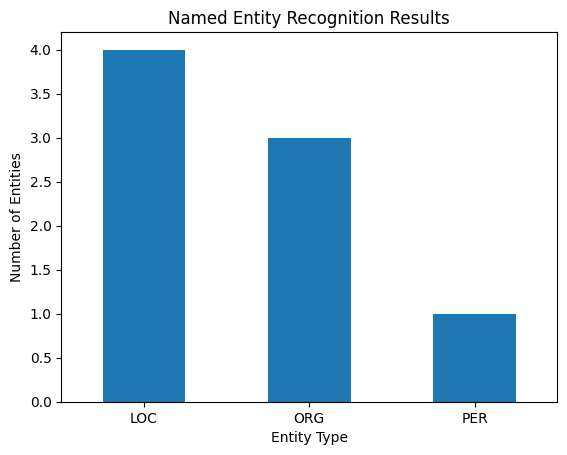

In [9]:
import matplotlib.pyplot as plt

if not df.empty:
    df["Entity Type"].value_counts().plot(
        kind="bar",
        title="Named Entity Recognition Results"
    )

    plt.xlabel("Entity Type")
    plt.ylabel("Number of Entities")
    plt.xticks(rotation=0)
    plt.show()
else:
    print("No named entities found.")